In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import smarts_cerebellum.globals as gl

segment = 'WM'
df = pd.read_csv(os.path.join(gl.baseDir, f'MNISymC_{segment}',f'summary_MNISymC_acoustic_radiation_{segment}_mod.tsv'), sep = '\t')

df['hemisphere'] = df.regionname.str[-1].str.lower()
patients = df[df.isPatient == 1]
controls = df[df.isPatient == 0]

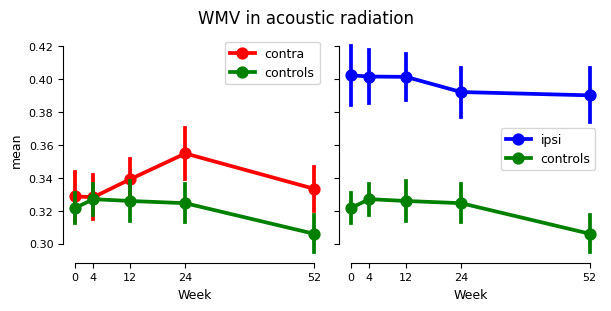

In [2]:
fig, axs = plt.subplots(1, 2, figsize = (6, 3), sharey = True, sharex = True, constrained_layout = True)

sns.pointplot(x = 'Week', y = 'mean', data = patients[patients.regionname == 'acoustic_R'], color = 'blue', label = 'ipsi', ax = axs[1], native_scale = True, errorbar = 'se')
sns.pointplot(x = 'Week', y = 'mean', data = patients[patients.regionname == 'acoustic_L'], color = 'red', label = 'contra', ax = axs[0], native_scale = True, errorbar = 'se')
sns.pointplot(x = 'Week', y = 'mean', data = controls, color = 'green', label = 'controls', ax = axs[0], native_scale = True, errorbar = 'se')
sns.pointplot(x = 'Week', y = 'mean', data = controls, color = 'green', label = 'controls', ax = axs[1], native_scale = True, errorbar = 'se')


for i in range(len(axs)):
    axs[i].set_xticks(gl.weeks)

fig.suptitle("WMV in acoustic radiation")
sns.despine(trim = True)
plt.show()